# 分類タスクの評価尺度と閾値調整（Fβ・特異度・不均衡データ・統計的有意差検定）

書籍 第1章「自然言語処理システムのデザイン」（1-4 評価：評価尺度とエラー分析、練習問題 2 など）に対応する演習ノートブックです。
CPU のみ・数秒で実行でき、追加ライブラリのインストールは不要です。

1. **基本 4 尺度と特異度（Specificity）・偽陽性率（FPR）**（p.33〜35、脚注 31）
2. **重み付き調和平均 $F_\beta$（$F_{0.5}$ / $F_1$ / $F_2$）と閾値調整**（「再現率 9 割固定時の適合率」p.34〜35）
3. **不均衡データにおける「正解率の罠」**
4. **多クラス分類の Macro 平均と Micro 平均**
5. **2 つのシステムの差は偶然か？：統計的有意差検定（対応のあるブートストラップ法と McNemar 検定）**（1-4 補足）

（※ 生成タスクの評価尺度 BLEU については、第 4 章の[機械翻訳の自動評価（BLEU）と対訳コーパスのノイズフィルタリング](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch4_bleu_corpus.ipynb)へ切り出しました。）

## 1. 準備

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    fbeta_score,
    precision_score,
    recall_score,
)

---

## 2. 分類タスクの評価尺度と特異度（定義式の実装と検証）

2値分類（正例 `1` / 負例 `0`）の予測結果から混同行列の 4 要素（TP, FP, FN, TN）を数え、定義式どおりに計算します。

- **正解率（Accuracy）**: $\displaystyle \frac{TP + TN}{TP + FP + FN + TN}$
- **適合率（Precision）**: $\displaystyle \frac{TP}{TP + FP}$（正例と予測したうち実際に正例だった割合）
- **再現率（Recall）**: $\displaystyle \frac{TP}{TP + FN}$（実際の正例のうち正しく検出できた割合）
- **特異度（Specificity）**: $\displaystyle \frac{TN}{TN + FP}$（実際の負例のうち正しく負例と予測できた割合。脚注 31）
- **偽陽性率（FPR）**: $\displaystyle \frac{FP}{TN + FP} = 1 - \text{Specificity}$（実際の負例のうち誤って正例と予測した割合）
- **$F_\beta$ スコア**: $\displaystyle (1 + \beta^2) \frac{\text{Precision} \cdot \text{Recall}}{(\beta^2 \cdot \text{Precision}) + \text{Recall}}$（$\beta=1$ が $F_1$、$\beta=0.5$ は適合率重視、$\beta=2$ は再現率重視）

In [2]:
def compute_binary_metrics(y_true, y_pred, beta=1.0):
    """混同行列から各種評価尺度を定義式どおりに計算する"""
    tp = sum(t == 1 and p == 1 for t, p in zip(y_true, y_pred))
    fp = sum(t == 0 and p == 1 for t, p in zip(y_true, y_pred))
    fn = sum(t == 1 and p == 0 for t, p in zip(y_true, y_pred))
    tn = sum(t == 0 and p == 0 for t, p in zip(y_true, y_pred))

    acc = (tp + tn) / (tp + fp + fn + tn)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    fpr = 1.0 - spec
    denom = (beta ** 2) * prec + rec
    fbeta = (1 + beta ** 2) * prec * rec / denom if denom > 0 else 0.0
    return {
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "accuracy": acc, "precision": prec, "recall": rec,
        "specificity": spec, "fpr": fpr, "fbeta": fbeta,
    }

y_true = [1, 1, 1, 1, 1, 0, 0, 0, 0, 0]
y_pred = [1, 1, 1, 0, 0, 1, 0, 0, 0, 0]

m1 = compute_binary_metrics(y_true, y_pred, beta=1.0)
m05 = compute_binary_metrics(y_true, y_pred, beta=0.5)
print(f"TP={m1['TP']}, FP={m1['FP']}, FN={m1['FN']}, TN={m1['TN']}")
print(
    f"手計算  : Acc={m1['accuracy']:.4f}, Prec={m1['precision']:.4f}, "
    f"Rec={m1['recall']:.4f}, Spec={m1['specificity']:.4f}, "
    f"F1={m1['fbeta']:.4f}, F0.5={m05['fbeta']:.4f}"
)
print(
    f"sklearn : Acc={accuracy_score(y_true, y_pred):.4f}, Prec={precision_score(y_true, y_pred):.4f}, "
    f"Rec={recall_score(y_true, y_pred):.4f}, "
    f"F1={fbeta_score(y_true, y_pred, beta=1.0):.4f}, F0.5={fbeta_score(y_true, y_pred, beta=0.5):.4f}"
)

TP=3, FP=1, FN=2, TN=4
手計算  : Acc=0.7000, Prec=0.7500, Rec=0.6000, Spec=0.8000, F1=0.6667, F0.5=0.7143
sklearn : Acc=0.7000, Prec=0.7500, Rec=0.6000, F1=0.6667, F0.5=0.7143


---

## 3. $F_\beta$ スコアと閾値調整（p.34〜35）

書籍 1-4-1（p.34〜35）では、アプリケーションの性質によって「適合率と再現率のどちらを重視するか」が変わることが解説されています。

- **誤検出を嫌う用途**（文法誤り訂正や一般ユーザ向け検索の上位表示）：**適合率重視（$F_{0.5}$）**
- **漏れを許せない用途**（特許検索で後段の専門家がチェックする前提）：**再現率重視（$F_2$、または「再現率が 9 割になる閾値での適合率」）**

モデルの予測確率に対して判定閾値を動かしたとき、Precision / Recall / Specificity / $F_{0.5}$ / $F_1$ / $F_2$ がどうトレードオフになるか確認してみましょう。

,閾値,Precision,Recall,Specificity,F0.5 (適合率重視),F1,F2 (再現率重視)
0,0.15,0.252,1.000,0.256,0.296,0.402,0.627
1,0.20,0.284,1.000,0.369,0.331,0.442,0.664
2,0.25,0.342,1.000,0.519,0.394,0.510,0.722
3,0.30,0.400,1.000,0.625,0.455,0.571,0.769
4,0.35,0.465,1.000,0.712,0.521,0.635,0.813
5,0.40,0.541,1.000,0.788,0.595,0.702,0.855
6,0.45,0.635,1.000,0.856,0.685,0.777,0.897
7,0.50,0.698,0.925,0.900,0.734,0.796,0.869
8,0.55,0.818,0.900,0.950,0.833,0.857,0.882
9,0.60,0.865,0.800,0.969,0.851,0.831,0.812


再現率>=0.90 で適合率最大の閾値: 0.55 (Recall=0.9, Precision=0.818)
F0.5 最大の閾値                : 0.7 (Recall=0.625, Precision=0.962)


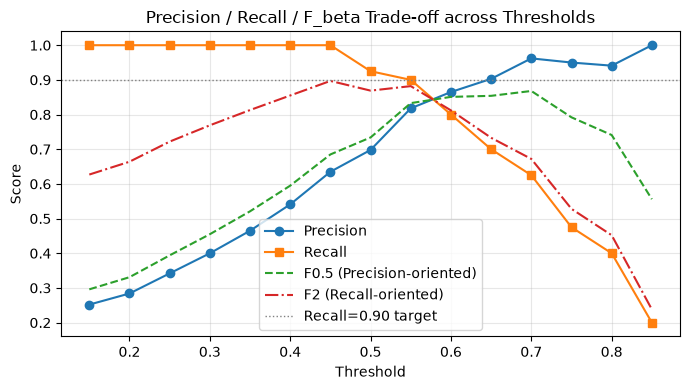

In [3]:
rng = np.random.default_rng(42)
n_pos, n_neg = 40, 160
y_scores = np.concatenate([rng.beta(4.5, 2.0, n_pos), rng.beta(1.8, 5.0, n_neg)])
y_labels = np.array([1] * n_pos + [0] * n_neg)

thresholds = np.round(np.linspace(0.15, 0.85, 15), 2)
records = []
for th in thresholds:
    pred = (y_scores >= th).astype(int)
    m1 = compute_binary_metrics(y_labels, pred, beta=1.0)
    m05 = compute_binary_metrics(y_labels, pred, beta=0.5)
    m2 = compute_binary_metrics(y_labels, pred, beta=2.0)
    records.append({
        "閾値": th,
        "Precision": round(m1["precision"], 3),
        "Recall": round(m1["recall"], 3),
        "Specificity": round(m1["specificity"], 3),
        "F0.5 (適合率重視)": round(m05["fbeta"], 3),
        "F1": round(m1["fbeta"], 3),
        "F2 (再現率重視)": round(m2["fbeta"], 3),
    })

df_th = pd.DataFrame(records)
display(df_th)

# 再現率 >= 0.90 を満たす範囲で最も適合率が高い閾値
rec90 = df_th[df_th["Recall"] >= 0.90]
best_rec90 = rec90.sort_values("Precision", ascending=False).iloc[0]
best_f05 = df_th.loc[df_th["F0.5 (適合率重視)"].idxmax()]
print(f"再現率>=0.90 で適合率最大の閾値: {best_rec90['閾値']} (Recall={best_rec90['Recall']}, Precision={best_rec90['Precision']})")
print(f"F0.5 最大の閾値                : {best_f05['閾値']} (Recall={best_f05['Recall']}, Precision={best_f05['Precision']})")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(df_th["閾値"], df_th["Precision"], marker="o", label="Precision")
ax.plot(df_th["閾値"], df_th["Recall"], marker="s", label="Recall")
ax.plot(df_th["閾値"], df_th["F0.5 (適合率重視)"], linestyle="--", label="F0.5 (Precision-oriented)")
ax.plot(df_th["閾値"], df_th["F2 (再現率重視)"], linestyle="-.", label="F2 (Recall-oriented)")
ax.axhline(0.90, color="gray", linestyle=":", linewidth=1, label="Recall=0.90 target")
ax.set_xlabel("Threshold")
ax.set_ylabel("Score")
ax.set_title("Precision / Recall / F_beta Trade-off across Thresholds")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- 誤検出を避けたい（適合率重視）タスクでは、**$F_{0.5}$ が最大になる高めの閾値 `0.70`（`Precision=0.962, Recall=0.625`）** が選ばれます。
- 逆に特許検索のように見逃しを減らしたい場合は閾値を下げ、**再現率 0.90 以上で適合率最大となる閾値 `0.55`（`Recall=0.900, Precision=0.818`）** や $F_2$ 重視の設定を選びます。

このセルでは、閾値選びの仕組みを確認するため、合成データを使っています。実際の評価では、開発データで閾値を選んで固定し、独立したテストデータで適合率・再現率を測ります。開発データで再現率が 0.90 に達しても、テストデータで同じ再現率になるとは限りません。

---

## 4. 不均衡データにおける「正解率の罠」

実際の NLP タスク（スパム検出、有害表現検出、希少な誤りの検出など）では、クラスの比率が大きく偏っている（**不均衡データ**）ことがよくあります。

100件のうち **95件が負例（0）、5件だけが正例（1）** というデータで、以下の 2 つのモデルを比較してみましょう。
- **モデル A（ダミー分類器）**: 入力を見ずに、すべて `0`（負例）と予測する
- **モデル B（実用的な分類器）**: 正例 5件のうち 4件を検出し、誤検出（FP）が 3件だけある

In [4]:
y_imb = [1] * 5 + [0] * 95
pred_dummy = [0] * 100
pred_model = [1, 1, 1, 1, 0] + [1, 1, 1] + [0] * 92

rows = []
for name, pred in [("モデルA（すべて0と予測）", pred_dummy), ("モデルB（正例を検出）", pred_model)]:
    rows.append({
        "モデル": name,
        "Accuracy": round(accuracy_score(y_imb, pred), 3),
        "Precision (正例)": round(precision_score(y_imb, pred, zero_division=0), 3),
        "Recall (正例)": round(recall_score(y_imb, pred, zero_division=0), 3),
        "F1 (正例)": round(f1_score(y_imb, pred, zero_division=0), 3),
        "Macro-F1": round(f1_score(y_imb, pred, average="macro", zero_division=0), 3),
    })

pd.DataFrame(rows)

,モデル,Accuracy,Precision (正例),Recall (正例),F1 (正例),Macro-F1
0,モデルA（すべて0と予測）,0.95,0.000,0.0,0.000,0.487
1,モデルB（正例を検出）,0.96,0.571,0.8,0.667,0.823


モデル A は何も検出していないにもかかわらず **Accuracy が 0.950** と非常に高く見えますが、正例の F1 は **0.000**、Macro-F1 も **0.487** にとどまります。不均衡データでは Accuracy だけでなく、適合率・再現率・F1（または Macro-F1）をあわせて確認することが重要です。

---

## 5. 多クラス分類の Macro 平均と Micro 平均

3クラス分類（`pos` / `neu` / `neg`）では、クラスごとの F1 をどのように集約するかによって値が大きく変わります。

- **Macro 平均**: 各クラスの F1 を**クラス数で単純平均**する（データ数が少ないクラスも対等に扱う）
- **Micro 平均**: 全クラスの TP・FP・FN を**合算してから**計算する（各事例を対等に扱うため、単一ラベル多クラス分類では Accuracy と一致する）

In [5]:
labels = ["pos", "neu", "neg"]
y_mc_true = ["pos"] * 40 + ["neu"] * 10 + ["neg"] * 10
y_mc_pred = (
    ["pos"] * 38 + ["neu"] * 2 +
    ["neu"] * 3  + ["pos"] * 7 +
    ["neg"] * 4  + ["pos"] * 6
)

print("混同行列（行: 正解 / 列: 予測）:")
display(pd.DataFrame(confusion_matrix(y_mc_true, y_mc_pred, labels=labels), index=labels, columns=labels))
print(classification_report(y_mc_true, y_mc_pred, labels=labels, digits=4))
print(f"Accuracy = {accuracy_score(y_mc_true, y_mc_pred):.4f}")
print(f"Micro-F1 = {f1_score(y_mc_true, y_mc_pred, average='micro'):.4f}")
print(f"Macro-F1 = {f1_score(y_mc_true, y_mc_pred, average='macro'):.4f}")

混同行列（行: 正解 / 列: 予測）:


,pos,neu,neg
pos,38,2,0
neu,7,3,0
neg,6,0,4


              precision    recall  f1-score   support

         pos     0.7451    0.9500    0.8352        40
         neu     0.6000    0.3000    0.4000        10
         neg     1.0000    0.4000    0.5714        10

    accuracy                         0.7500        60
   macro avg     0.7817    0.5500    0.6022        60
weighted avg     0.7634    0.7500    0.7187        60

Accuracy = 0.7500
Micro-F1 = 0.7500
Macro-F1 = 0.6022


---

## 6. 2 つのシステムの差は偶然か？：統計的有意差検定（対応のあるブートストラップ法と McNemar 検定）（1-4 補足）

テストデータ上でモデル B がモデル A より Accuracy や Macro-$F_1$ で `+0.02〜+0.03` 上回ったとき、それが**本質的な改善なのか、限られた評価データの偶然の揺らぎなのか**を判断するには**統計的有意差検定**が必要です。

1. **McNemar 検定（Accuracy の対応比較）**: 同一テストセット上の 2 つの予測から $2 \times 2$ 分割表（両方正解 $a$・A のみ正解 $b$・B のみ正解 $c$・両方不正解 $d$）を作り、意見が分かれた事例 $(b, c)$ に着目します。帰無仮説 $p = 0.5$ のもとでの**正確二項検定(two-sided exact $p$-value)**と、連続性補正付き $\chi^2$ 統計量 $\chi^2_{\mathrm{cc}} = \frac{(|b - c| - 1)^2}{b + c}$ を実装します。
2. **対応のあるブートストラップ法(Paired Bootstrap Resampling; Koehn 2004)**: Macro-$F_1$ のように分割表だけでは検定できない非線形指標でも、同じテスト事例インデックスを復元抽出（$B = 5{,}000$ 回）して差の分布 $\Delta^* = M(B) - M(A)$ を求めることで、**95% 信頼区間 (CI)** と **$p$ 値**を直接計算できます。

ここでは $N = 200$ 件の不均衡 3 クラス分類（`pos`: 100 件, `neu`: 50 件, `neg`: 50 件）において、次の 3 モデルを比較します。
- **`Baseline A`**
- **`Small Noisy Difference B1`**: 一部の誤りを直すが別の正解を壊しており、見かけの点推定は `+0.025〜+0.030` 高いが偶然の範囲内($p > 0.05$)
- **`Systematic Improvement B2`**: 少数クラス(`neu`/`neg`)の誤りを系統的に改善しており統計的に有意($p < 0.05$)

In [6]:
from scipy.stats import binomtest, chi2

def fast_macro_f1(y_true, y_pred, n_classes=3):
    cm = np.bincount(y_true * n_classes + y_pred, minlength=n_classes * n_classes).reshape(n_classes, n_classes)
    tp = np.diag(cm)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    denom = 2 * tp + fp + fn
    return float(np.where(denom > 0, 2 * tp / np.maximum(denom, 1), 0.0).mean())

def batch_macro_f1(yt_batch, yp_batch, n_classes=3):
    '''(B, N) バッチに対してベクトル化計算で Macro-F1 を一括算出する'''
    B = yt_batch.shape[0]
    codes = yt_batch * n_classes + yp_batch
    offsets = np.arange(B)[:, None] * (n_classes * n_classes)
    cms = np.bincount((codes + offsets).ravel(), minlength=B * n_classes * n_classes).reshape(B, n_classes, n_classes)
    tp = np.diagonal(cms, axis1=1, axis2=2)
    fp = cms.sum(axis=1) - tp
    fn = cms.sum(axis=2) - tp
    denom = 2 * tp + fp + fn
    f1s = np.where(denom > 0, 2 * tp / np.maximum(denom, 1), 0.0)
    return f1s.mean(axis=1)

def mcnemar_test(y_true, pred_a, pred_b):
    corr_a = (y_true == pred_a)
    corr_b = (y_true == pred_b)
    a = int(np.sum(corr_a & corr_b))
    b = int(np.sum(corr_a & ~corr_b))
    c = int(np.sum(~corr_a & corr_b))
    d = int(np.sum(~corr_a & ~corr_b))
    n_disc = b + c
    if n_disc == 0:
        return {"a": a, "b": b, "c": c, "d": d, "p_exact": 1.0, "chi2_cc": 0.0, "p_chi2": 1.0}
    p_exact = float(binomtest(min(b, c), n_disc, 0.5, alternative="two-sided").pvalue)
    chi2_cc = (max(abs(b - c) - 1, 0) ** 2) / n_disc
    p_chi2 = float(chi2.sf(chi2_cc, df=1))
    return {"a": a, "b": b, "c": c, "d": d, "p_exact": p_exact, "chi2_cc": chi2_cc, "p_chi2": p_chi2}

def paired_bootstrap_test(y_true, pred_a, pred_b, n_boot=5000, seed=42, n_classes=3):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    idx = rng.integers(0, n, size=(n_boot, n))
    yt_b, pa_b, pb_b = y_true[idx], pred_a[idx], pred_b[idx]

    acc_diffs = (pb_b == yt_b).mean(axis=1) - (pa_b == yt_b).mean(axis=1)
    f1_diffs = batch_macro_f1(yt_b, pb_b, n_classes) - batch_macro_f1(yt_b, pa_b, n_classes)

    obs_acc = float(np.mean(pred_b == y_true) - np.mean(pred_a == y_true))
    obs_f1 = fast_macro_f1(y_true, pred_b, n_classes) - fast_macro_f1(y_true, pred_a, n_classes)

    def summarize(diffs, obs):
        ci_lo, ci_hi = np.percentile(diffs, [2.5, 97.5])
        p_two = float(min(1.0, 2.0 * min(np.mean(diffs <= 0.0), np.mean(diffs >= 0.0))))
        win_rate = float(np.mean(diffs > 0.0))
        return {"obs_diff": obs, "ci_lo": float(ci_lo), "ci_hi": float(ci_hi), "p_boot": p_two, "win_rate": win_rate}

    return summarize(acc_diffs, obs_acc), summarize(f1_diffs, obs_f1), f1_diffs

# 1. N=200 の 3 クラス不均衡テストデータ（0=pos: 100, 1=neu: 50, 2=neg: 50）
y_sig_true = np.array([0] * 100 + [1] * 50 + [2] * 50)
pred_A = y_sig_true.copy()
pred_A[0:10] = 1
pred_A[100:118] = 0
pred_A[150:166] = 0
pred_A[166:170] = 1

# B1: 14 事例を改善するが 9 事例で新たに誤る（偶然の揺らぎで説明可能）
pred_B1 = pred_A.copy()
pred_B1[0:4] = 0
pred_B1[100:105] = 1
pred_B1[150:155] = 2
pred_B1[10:14] = 1
pred_B1[120:123] = 0
pred_B1[170:172] = 0

# B2: 少数クラスを中心に 16 事例を改善し、悪化は 2 事例のみ（系統的改善）
pred_B2 = pred_A.copy()
pred_B2[100:108] = 1
pred_B2[150:158] = 2
pred_B2[10:12] = 1

# sklearn の Macro-F1 との一致を検証
for name, p in [("Baseline A", pred_A), ("Noisy Diff B1", pred_B1), ("Systematic B2", pred_B2)]:
    assert abs(fast_macro_f1(y_sig_true, p) - f1_score(y_sig_true, p, average="macro")) < 1e-12

model_summary = pd.DataFrame([
    {"システム": name, "Accuracy": round(accuracy_score(y_sig_true, p), 3), "Macro-F1": round(fast_macro_f1(y_sig_true, p), 3)}
    for name, p in [("Baseline A", pred_A), ("Small Noisy Diff B1", pred_B1), ("Systematic Imp. B2", pred_B2)]
])
print("=== テストデータ (N=200) 上の性能 ===")
display(model_summary)

mc_b1 = mcnemar_test(y_sig_true, pred_A, pred_B1)
mc_b2 = mcnemar_test(y_sig_true, pred_A, pred_B2)
acc_b1, f1_b1, f1_diffs_b1 = paired_bootstrap_test(y_sig_true, pred_A, pred_B1, n_boot=5000, seed=42)
acc_b2, f1_b2, f1_diffs_b2 = paired_bootstrap_test(y_sig_true, pred_A, pred_B2, n_boot=5000, seed=42)

sig_table = pd.DataFrame([
    {
        "比較": "B1 vs A (Noisy)",
        "McNemar (a/b/c/d)": f"{mc_b1['a']}/{mc_b1['b']}/{mc_b1['c']}/{mc_b1['d']}",
        "McNemar Exact p": round(mc_b1["p_exact"], 4),
        "McNemar chi2_cc": round(mc_b1["chi2_cc"], 3),
        "Boot Acc Diff [95% CI]": f"{acc_b1['obs_diff']:+.3f} [{acc_b1['ci_lo']:+.3f}, {acc_b1['ci_hi']:+.3f}]",
        "Boot F1 Diff [95% CI]": f"{f1_b1['obs_diff']:+.3f} [{f1_b1['ci_lo']:+.3f}, {f1_b1['ci_hi']:+.3f}]",
        "Boot F1 p": round(f1_b1["p_boot"], 4),
        "有意判定 (alpha=0.05)": "有意でない (n.s.)" if f1_b1["p_boot"] >= 0.05 else "有意 (*)",
    },
    {
        "比較": "B2 vs A (Systematic)",
        "McNemar (a/b/c/d)": f"{mc_b2['a']}/{mc_b2['b']}/{mc_b2['c']}/{mc_b2['d']}",
        "McNemar Exact p": round(mc_b2["p_exact"], 4),
        "McNemar chi2_cc": round(mc_b2["chi2_cc"], 3),
        "Boot Acc Diff [95% CI]": f"{acc_b2['obs_diff']:+.3f} [{acc_b2['ci_lo']:+.3f}, {acc_b2['ci_hi']:+.3f}]",
        "Boot F1 Diff [95% CI]": f"{f1_b2['obs_diff']:+.3f} [{f1_b2['ci_lo']:+.3f}, {f1_b2['ci_hi']:+.3f}]",
        "Boot F1 p": round(f1_b2["p_boot"], 4),
        "有意判定 (alpha=0.05)": "有意でない (n.s.)" if f1_b2["p_boot"] >= 0.05 else "有意 (**)",
    },
])
print("\n=== McNemar 検定および対応のあるブートストラップ検定 (B=5000) の結果 ===")
display(sig_table)

=== テストデータ (N=200) 上の性能 ===


,システム,Accuracy,Macro-F1
0,Baseline A,0.760,0.740
1,Small Noisy Diff B1,0.785,0.770
2,Systematic Imp. B2,0.830,0.824



=== McNemar 検定および対応のあるブートストラップ検定 (B=5000) の結果 ===


,比較,McNemar (a/b/c/d),McNemar Exact p,McNemar chi2_cc,Boot Acc Diff [95% CI],Boot F1 Diff [95% CI],Boot F1 p,有意判定 (alpha=0.05)
0,B1 vs A (Noisy),143/9/14/34,0.4049,0.696,"+0.025 [-0.020, +0.075]","+0.030 [-0.020, +0.084]",0.2476,有意でない (n.s.)
1,B2 vs A (Systematic),150/2/16/32,0.0013,9.389,"+0.070 [+0.030, +0.110]","+0.084 [+0.041, +0.133]",0.0000,有意 (**)


=== 同一の真の差 (Macro-F1 約 +0.06) に対するサンプルサイズ別の CI 幅と検出力 ===


,N,平均 95% CI 幅,検出力 (McNemar),検出力 (Bootstrap F1)
0,50,0.175,0.120,0.385
1,100,0.125,0.465,0.595
2,200,0.088,0.845,0.885
3,500,0.056,1.000,1.000


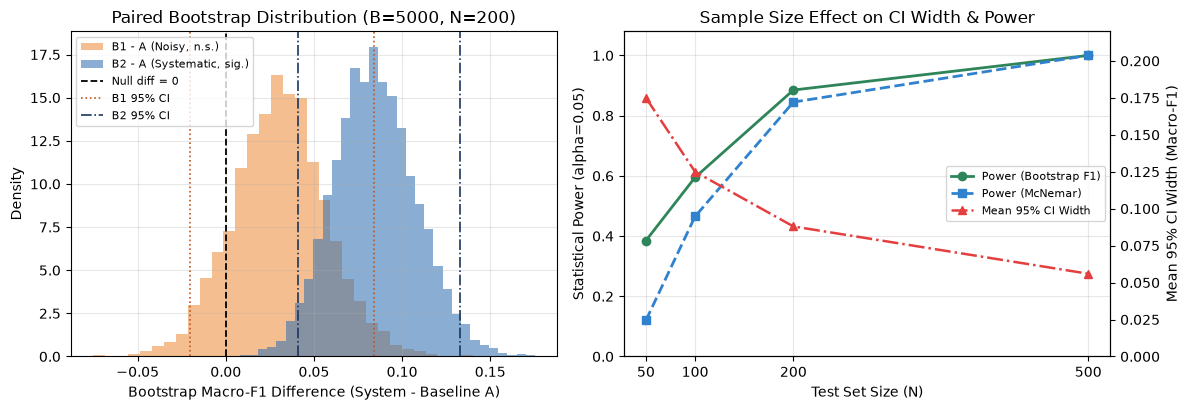

In [7]:
# 2. サンプルサイズ N in {50, 100, 200, 500} が信頼区間幅と検出力 (Statistical Power) に与える影響
rng_sim = np.random.default_rng(123)
sample_sizes = [50, 100, 200, 500]
n_trials = 200
n_boot_sim = 500
size_rows = []

for N in sample_sizes:
    ci_widths = []
    mc_sig_cnt = 0
    bt_sig_cnt = 0
    for _ in range(n_trials):
        y = rng_sim.choice([0, 1, 2], size=N, p=[0.5, 0.25, 0.25])
        err_a = rng_sim.random(N) < 0.24
        pa = np.where(err_a, (y + rng_sim.integers(1, 3, size=N)) % 3, y)
        fix_b = err_a & (rng_sim.random(N) < 0.35)
        reg_b = (~err_a) & (rng_sim.random(N) < 0.02)
        pb = y.copy()
        pb[err_a & ~fix_b] = pa[err_a & ~fix_b]
        pb[reg_b] = (y[reg_b] + 1) % 3

        if mcnemar_test(y, pa, pb)["p_exact"] < 0.05:
            mc_sig_cnt += 1
        idx = rng_sim.integers(0, N, size=(n_boot_sim, N))
        diffs = batch_macro_f1(y[idx], pb[idx]) - batch_macro_f1(y[idx], pa[idx])
        lo, hi = np.percentile(diffs, [2.5, 97.5])
        ci_widths.append(float(hi - lo))
        p_bt = min(1.0, 2.0 * min(float(np.mean(diffs <= 0.0)), float(np.mean(diffs >= 0.0))))
        if p_bt < 0.05:
            bt_sig_cnt += 1

    size_rows.append({
        "N": N,
        "平均 95% CI 幅": round(float(np.mean(ci_widths)), 3),
        "検出力 (McNemar)": round(mc_sig_cnt / n_trials, 3),
        "検出力 (Bootstrap F1)": round(bt_sig_cnt / n_trials, 3),
    })

df_size = pd.DataFrame(size_rows)
print("=== 同一の真の差 (Macro-F1 約 +0.06) に対するサンプルサイズ別の CI 幅と検出力 ===")
display(df_size)

# 3. 可視化（英語表記ラベルのみ）
fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.2))

# Left: Bootstrap Delta Macro-F1 distributions
axes[0].hist(f1_diffs_b1, bins=32, alpha=0.55, color="#ed8936", density=True, label="B1 - A (Noisy, n.s.)")
axes[0].hist(f1_diffs_b2, bins=32, alpha=0.55, color="#2b6cb0", density=True, label="B2 - A (Systematic, sig.)")
axes[0].axvline(0.0, color="black", linestyle="--", linewidth=1.3, label="Null diff = 0")
axes[0].axvline(f1_b1["ci_lo"], color="#c05621", linestyle=":", linewidth=1.2)
axes[0].axvline(f1_b1["ci_hi"], color="#c05621", linestyle=":", linewidth=1.2, label="B1 95% CI")
axes[0].axvline(f1_b2["ci_lo"], color="#1a365d", linestyle="-.", linewidth=1.2)
axes[0].axvline(f1_b2["ci_hi"], color="#1a365d", linestyle="-.", linewidth=1.2, label="B2 95% CI")
axes[0].set_xlabel("Bootstrap Macro-F1 Difference (System - Baseline A)")
axes[0].set_ylabel("Density")
axes[0].set_title("Paired Bootstrap Distribution (B=5000, N=200)")
axes[0].legend(fontsize=8, loc="upper left")
axes[0].grid(alpha=0.3)

# Right: Sample size effect on CI width and power
ax_r1 = axes[1]
ax_r2 = ax_r1.twinx()
l1 = ax_r1.plot(df_size["N"], df_size["検出力 (Bootstrap F1)"], marker="o", color="#2f855a", linewidth=2, label="Power (Bootstrap F1)")
l2 = ax_r1.plot(df_size["N"], df_size["検出力 (McNemar)"], marker="s", color="#3182ce", linestyle="--", linewidth=2, label="Power (McNemar)")
l3 = ax_r2.plot(df_size["N"], df_size["平均 95% CI 幅"], marker="^", color="#e53e3e", linestyle="-.", linewidth=1.8, label="Mean 95% CI Width")
ax_r1.set_xticks(sample_sizes)
ax_r1.set_xlabel("Test Set Size (N)")
ax_r1.set_ylabel("Statistical Power (alpha=0.05)")
ax_r2.set_ylabel("Mean 95% CI Width (Macro-F1)")
ax_r1.set_ylim(0.0, 1.08)
ax_r2.set_ylim(0.0, 0.22)
ax_r1.set_title("Sample Size Effect on CI Width & Power")
lines = l1 + l2 + l3
labels = [l.get_label() for l in lines]
ax_r1.legend(lines, labels, loc="center right", fontsize=8)
ax_r1.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 観察とまとめ（第 6 節）

- **点推定の `+0.02〜+0.03` に騙されない**: `B1` は Macro-$F_1$ で `+0.030`、Accuracy で `+0.025` 上回りますが、McNemar 検定の不一致事例は $b=9, c=14$ と拮抗しており($p = 0.405$)、ブートストラップ 95% 信頼区間も `[-0.020, +0.084]` と `0` を跨ぐため、偶然の差を否定できません。
- **系統的改善の検出**: `B2` は悪化を $b=2$ に抑えつつ $c=16$ 事例を改善しており、McNemar 検定($p = 0.0013$)およびブートストラップ検定(95% CI `[+0.041, +0.133]`, $p < 0.001$)の双方で有意差が確認できます。
- **サンプルサイズと検出力**: 同じ実力差（Macro-$F_1$ 約 `+0.06`）があっても、$N = 50$ の小規模評価では 95% 信頼区間幅が約 `0.17`〜`0.18` と広く検出力も低いため本物の改善を見逃しやすく、$N \ge 200$ 程度を確保することで信頼区間が狭まり高い検出力を得られます。